In [11]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

In [12]:
# Cell 2: Automated Dataset Download & Load
import kagglehub
import pandas as pd
import os

print("Downloading/Checking latest AutoScout24 dataset...")
# This checks if the dataset is already downloaded; if not, it downloads it instantly
download_path = kagglehub.dataset_download("clkmuhammed/autoscout24-car-listings-dataset")

# Find the .csv file inside the downloaded directory
csv_filename = "autoscout24-car-listings-dataset.csv" 
full_csv_path = os.path.join(download_path, csv_filename)

# Check if file exists, if not, list files in directory to ensure we get the right filename
if not os.path.exists(full_csv_path):
    files = os.listdir(download_path)
    csv_files = [f for f in files if f.endswith('.csv')]
    if csv_files:
        full_csv_path = os.path.join(download_path, csv_files[0])

print(f"Loading dataset from: {full_csv_path}")
df = pd.read_csv(full_csv_path)

# Preview the data structure
print(f"Dataset Dimensions: {df.shape}")
print(df.info())
display(df.head())

Downloading/Checking latest AutoScout24 dataset...
Loading dataset from: C:\Users\ASUS\.cache\kagglehub\datasets\clkmuhammed\autoscout24-car-listings-dataset\versions\2\autoscout24_dataset_20251108.csv
Dataset Dimensions: (118382, 75)
<class 'pandas.DataFrame'>
RangeIndex: 118382 entries, 0 to 118381
Data columns (total 75 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   id                                    118382 non-null  str    
 1   description                           113990 non-null  str    
 2   ratings_average                       76428 non-null   str    
 3   ratings_count                         76428 non-null   float64
 4   ratings_recommend_percentage          76428 non-null   float64
 5   price_currency                        118382 non-null  str    
 6   price                                 118382 non-null  float64
 7   price_tax_deductible                  118382 non

,id,description,ratings_average,ratings_count,ratings_recommend_percentage,price_currency,price,price_tax_deductible,price_negotiable,price_net,...,zip,city,street,latitude,longitude,seller_is_dealer,seller_type,seller_company_name,has_warranty,warranty
0,001c08bb-96f9-4198-a2c9-39bcab088a08,"Deze Suzuki Swift is maatje S, maar hij valt e...",NaN,NaN,NaN,EUR,22950.0,True,False,19279.0,...,8801 PN,FRANEKER,Edisonstraat 1,53.18188,5.52596,True,Dealer,Haaima Franeker,NaN,NaN
1,00918c06-f736-404a-b55a-0ccd1d876129,"Kraftvoll, komfortabel, kompromisslos: BMW X3 ...",NaN,NaN,NaN,EUR,46000.0,False,False,NaN,...,81476,München,NaN,48.09126,11.49140,False,PrivateSeller,NaN,NaN,NaN
2,0083e29f-8030-4478-b662-6dff92e22a06,<strong>Highlights:</strong><br /><ul><li><str...,"4,8",124.0,0.0,EUR,179900.0,False,False,NaN,...,9830,Sint-Martens-Latem,Kortrijksesteenweg 168,51.00730,3.62822,True,Dealer,Garage Vandenberghe,NaN,NaN
3,00617c58-7172-49ff-8dc6-cd876ff5f7e8,Veicolo in promozione con la formula &quot;GUI...,"4,2",253.0,83.0,EUR,70400.0,True,False,NaN,...,30035,Mirano - Venezia - Ve,"Via Della Vittoria, 132/A",45.49315,12.12426,True,Dealer,Ongarato Motors Srl,NaN,NaN
4,00519a06-60a2-4dea-8431-9ec21add3172,De verkoopprijs van deze auto is inclusief een...,NaN,NaN,NaN,EUR,66999.0,False,False,NaN,...,7121 BG,AALTEN,Bredevoortsestraatweg 119,51.93223,6.59322,True,Dealer,Automobielbedrijf Blekkink Aalten,NaN,NaN


In [13]:
# Cell 3: Feature Extraction & Data Type Synchronization

# 1. Drop rows where target valuation data is missing
df = df.dropna(subset=['price'])

# 2. Match exact column names found in your 75-column Kaggle printout
# Adjust these strings if the kaggle column headers are named differently (e.g., 'mileage' vs 'mileage_km')
features = ['make', 'model', 'mileage_km', 'production_year', 'power_hp', 'transmission']
target = 'price'

# Filter dataset to only keep what our web interface uses
df = df[features + [target]]

# 3. Clean 'mileage_km' if it contains string formatting like "5,180 km"
if df['mileage_km'].dtype == 'object':
    df['mileage_km'] = df['mileage_km'].astype(str)
    # Remove variations of 'km' suffix (handles spaces before/after)
    df['mileage_km'] = df['mileage_km'].str.replace(r'[\s]*km[\s]*$', '', case=False, regex=True)
    # Remove commas
    df['mileage_km'] = df['mileage_km'].str.replace(',', '', regex=False)
    # Convert to numeric, coercing errors to NaN
    df['mileage_km'] = pd.to_numeric(df['mileage_km'], errors='coerce')

# 4. Clean 'power_hp' if it has any text or structural anomalies
if df['power_hp'].dtype == 'object':
    df['power_hp'] = pd.to_numeric(df['power_hp'], errors='coerce')

# 5. Clean 'production_year' to ensure it's a valid integer
df['production_year'] = pd.to_numeric(df['production_year'], errors='coerce')

# Clear out any rows that became null during data type conversions
df = df.dropna()

print(f"Final Cleaned Dataset Matrix Shape: {df.shape}")
print("\nVerified Data Types for Production Pipeline:")
print(df.dtypes)

Final Cleaned Dataset Matrix Shape: (21346, 7)

Verified Data Types for Production Pipeline:
make                   str
model                  str
mileage_km             str
production_year    float64
power_hp           float64
transmission           str
price              float64
dtype: object


In [14]:
# Cell 4: Split data
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features: {X_train.shape}, Testing features: {X_test.shape}")

Training features: (17076, 6), Testing features: (4270, 6)


In [17]:
# Cell 5: Define Transformers & Pipeline

# Define columns by data type
categorical_cols = ['make', 'model', 'transmission']
numerical_cols = ['mileage_km', 'production_year', 'power_hp']

# 1. Preprocessing for numerical data: Scale to uniform variance
numerical_transformer = StandardScaler()

# 2. Preprocessing for categorical data: One-Hot Encode text features
# handle_unknown='ignore' is critical so your app doesn't crash if a user inputs a rare car model
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Combine preprocessors
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# Define the complete model pipeline using a Random Forest Regressor
# (You can swap this for XGBoost or LightGBM later if you prefer)
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Train the entire model pipeline in one line!
# Clean the split data before fitting the pipeline
for _X_name, _y_name in [('X_train', 'y_train'), ('X_test', 'y_test')]:
    _X = globals()[_X_name].copy()
    _y = globals()[_y_name].copy()

    _X['mileage_km'] = (
        _X['mileage_km'].astype(str)
        .str.replace(r'[\s]*km[\s]*$', '', case=False, regex=True)
        .str.replace(',', '', regex=False)
    )
    _X['mileage_km'] = pd.to_numeric(_X['mileage_km'], errors='coerce')
    _X['production_year'] = pd.to_numeric(_X['production_year'], errors='coerce')
    _X['power_hp'] = pd.to_numeric(_X['power_hp'], errors='coerce')

    _valid = _X.notna().all(axis=1) & _y.notna()
    globals()[_X_name] = _X.loc[_valid].copy()
    globals()[_y_name] = _y.loc[_valid].copy()

model_pipeline.fit(X_train, y_train)
print("Model training complete.")


Model training complete.


Mean Absolute Error (MAE): €5650.49
Root Mean Squared Error (RMSE): €15949.50
R² Score (Accuracy Metric): 0.8979


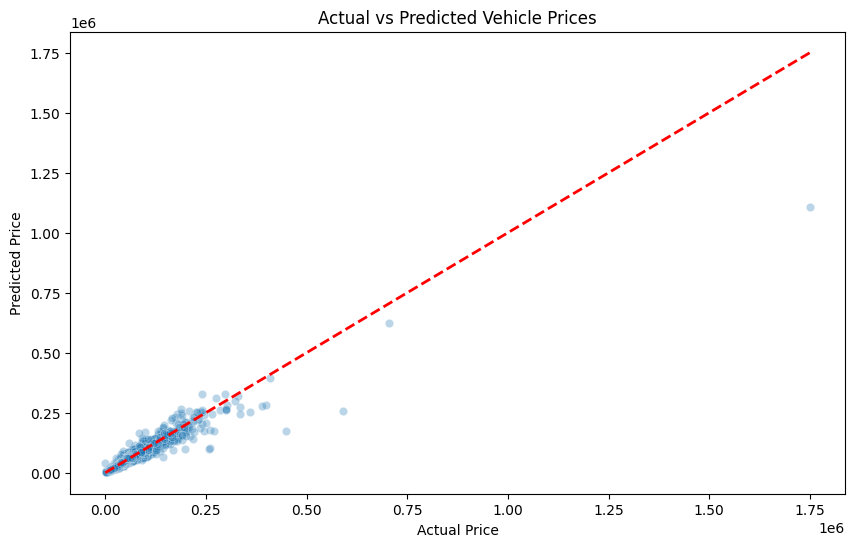

In [18]:
# Cell 6: Evaluation
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): €{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): €{rmse:.2f}")
print(f"R² Score (Accuracy Metric): {r2:.4f}")

# Quick visual check: Actual vs Predicted Prices
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Vehicle Prices')
plt.show()

In [19]:
# Cell 7: Exporting Pipeline
import os

# Create models directory if it doesn't exist
os.makedirs('../src/models', exist_ok=True)

# Save the trained model pipeline
joblib.dump(model_pipeline, '../src/models/car_price_pipeline.pkl')
print("Pipeline successfully exported to 'src/models/car_price_pipeline.pkl'")

Pipeline successfully exported to 'src/models/car_price_pipeline.pkl'
